# Paper 03: Batch Normalization
**Authors**: Sergey Ioffe & Christian Szegedy (2015)

---

## 1. The Historical Problem (Internal Covariate Shift)
In deep networks, training was painfully slow because as early layers update, the distribution of inputs to deeper layers shifts constantly.
Practitioners were forced to use tiny learning rates ($10^{-4}$) and delicate initializations to avoid exploding or saturated activations.

## 2. The First-Principles Solution
1. **Standardize Mini-Batch Activations**: Force mean 0 and variance 1 across the mini-batch:
   $$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$
2. **Restore Representation Power (Learnable Affine)**: Multiply by scale $\gamma$ and add shift $\beta$:
   $$y = \gamma \hat{x} + \beta$$
3. **Inference with Running Buffers**: Track running mean and variance via EMA during training so inference on single samples ($B=1$) works deterministically.

In this exercise, you will implement `BatchNorm1d` and `BatchNorm2d` in `model.py` and test them here.

---
## Setup
`%autoreload 2` ensures any edits you make in `model.py` are immediately refreshed.

In [4]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import BatchNorm1d, BatchNorm2d
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: BatchNorm1d Testing

We test that `BatchNorm1d`:
1. Normalizes mini-batches to mean 0.0 and std 1.0.
2. Correctly scales and shifts with learnable $\gamma$ and $\beta$.
3. Accumulates running buffers and runs in `eval()` mode on a single sample ($B=1$).

In [5]:
print("Testing BatchNorm1d Training Stats:")
tests.test_batchnorm1d_training_stats(BatchNorm1d)

print("\nTesting BatchNorm1d Affine Parameters:")
tests.test_batchnorm1d_affine(BatchNorm1d)

print("\nTesting BatchNorm1d Running Stats & Eval Mode:")
tests.test_batchnorm1d_running_stats_and_eval(BatchNorm1d)

Testing BatchNorm1d Training Stats:
  [PASS] BatchNorm1d correctly standardizes batch to mean 0.0 and std 1.0!

Testing BatchNorm1d Affine Parameters:
  [PASS] Learnable affine parameters (gamma=2.5, beta=-1.5) scale and shift correctly!

Testing BatchNorm1d Running Stats & Eval Mode:
  [PASS] Running stats updated (mean: 2.66, var: 3.55) and eval(B=1) works flawlessly!


True

---
## Part 2: BatchNorm2d Spatial Feature Map Normalization

For 2D convolutions with shape $(B, C, H, W)$, Batch Normalization standardizes each channel across all pixels in the batch ($B \times H \times W$).

In [6]:
print("Testing BatchNorm2d Spatial Normalization:")
tests.test_batchnorm2d_spatial(BatchNorm2d)

print("\nTesting Equivalence to PyTorch Native BatchNorm:")
tests.test_equivalence_to_pytorch(BatchNorm1d, BatchNorm2d)

Testing BatchNorm2d Spatial Normalization:
  [PASS] BatchNorm2d correctly normalizes across all spatial pixels per channel!

Testing Equivalence to PyTorch Native BatchNorm:
  [PASS] Custom BatchNorm is mathematically identical to PyTorch native (diff1d: 2.38e-07, diff2d: 4.77e-07)!


True

---
## Part 3: The Grand Experiment: Training With vs Without BatchNorm

We train an 8-layer deep network under a high learning rate ($\text{lr} = 0.05$):
1. **Without BatchNorm**: Activations drift, training is unstable and noisy.
2. **With Your BatchNorm**: Training is completely stabilized, and loss drops rapidly!

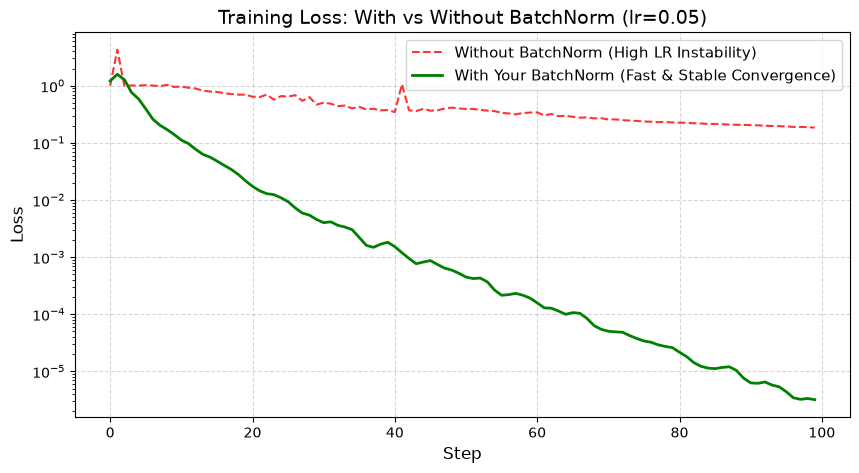

Final Loss -> Without BN: 0.1849 | With Your BN: 0.000003


In [7]:
torch.manual_seed(42)

# Build Model WITHOUT BatchNorm
def build_net_without_bn():
    layers = []
    for i in range(8):
        d_in = 32 if i == 0 else 64
        d_out = 2 if i == 7 else 64
        layers.append(nn.Linear(d_in, d_out))
        if i < 7:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)

# Build Model WITH BatchNorm
def build_net_with_bn():
    layers = []
    for i in range(8):
        d_in = 32 if i == 0 else 64
        d_out = 2 if i == 7 else 64
        layers.append(nn.Linear(d_in, d_out))
        if i < 7:
            layers.append(BatchNorm1d(64))
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)

batch_x = torch.randn(64, 32)
batch_y = torch.randn(64, 2)
loss_fn = nn.MSELoss()

def train_model(model, steps=100):
    opt = AdamW(model.parameters(), lr=0.05, weight_decay=0.0)
    losses = []
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(batch_x), batch_y)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

losses_no_bn = train_model(build_net_without_bn())
losses_with_bn = train_model(build_net_with_bn())

plt.figure(figsize=(10, 5))
plt.plot(losses_no_bn, 'r--', label='Without BatchNorm (High LR Instability)', alpha=0.8)
plt.plot(losses_with_bn, 'g-', label='With Your BatchNorm (Fast & Stable Convergence)', linewidth=2)
plt.title('Training Loss: With vs Without BatchNorm (lr=0.05)', fontsize=14)
plt.xlabel('Step', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

print(f"Final Loss -> Without BN: {losses_no_bn[-1]:.4f} | With Your BN: {losses_with_bn[-1]:.6f}")